=== BẢNG TỔNG HỢP GIÁ TRỊ F-MEASURE CỦA CÁC BÀI TẬP CƠ BẢN ===


,Thuật toán (Bài tập cơ bản),Precision,Recall,F-measure (Công thức),F1-score (Sklearn kiểm chứng)
0,Cây quyết định ID3 (Entropy),0.9650,0.9649,0.9649,0.9648
1,Cây quyết định CART (Gini),0.9433,0.9415,0.9424,0.9419
2,Naïve Bayes (GaussianNB),0.9414,0.9415,0.9415,0.9413


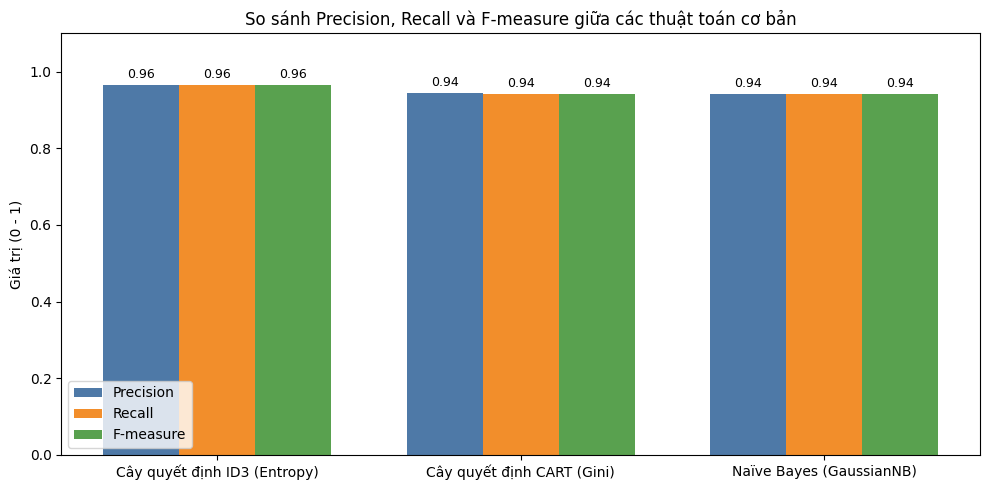

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import precision_score, recall_score, f1_score

# 1. Tải bộ dữ liệu mẫu đại diện cho các bài tập cơ bản (có thể thay bằng dữ liệu heart.csv của bạn)
data = datasets.load_breast_cancer() # Hoặc thay bằng X, y của bài tập cơ bản trong Lab
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.3, random_state=42
)

# 2. Khởi tạo 3 mô hình thuật toán của các bài tập cơ bản
models = {
    "Cây quyết định ID3 (Entropy)": DecisionTreeClassifier(criterion="entropy", random_state=42),
    "Cây quyết định CART (Gini)": DecisionTreeClassifier(criterion="gini", random_state=42),
    "Naïve Bayes (GaussianNB)": GaussianNB()
}

# 3. Huấn luyện, tính Precision, Recall và F-measure theo công thức đề bài
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Tính Precision và Recall (trung bình weighted cho các lớp)
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')

    # Tính F-measure theo đúng công thức trong đề bài: 2 * (P * R) / (P + R)
    f_measure = 2 * (precision * recall) / (precision + recall)

    results.append({
        "Thuật toán (Bài tập cơ bản)": name,
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F-measure (Công thức)": round(f_measure, 4),
        "F1-score (Sklearn kiểm chứng)": round(f1_score(y_test, y_pred, average='weighted'), 4)
    })

# 4. Hiển thị bảng kết quả tổng hợp
df_results = pd.DataFrame(results)
print("=== BẢNG TỔNG HỢP GIÁ TRỊ F-MEASURE CỦA CÁC BÀI TẬP CƠ BẢN ===")
display(df_results)

# 5. Vẽ biểu đồ trực quan so sánh Precision, Recall và F-measure
x = np.arange(len(df_results))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))
rects1 = ax.bar(x - width, df_results["Precision"], width, label='Precision', color='#4e79a7')
rects2 = ax.bar(x, df_results["Recall"], width, label='Recall', color='#f28e2b')
rects3 = ax.bar(x + width, df_results["F-measure (Công thức)"], width, label='F-measure', color='#59a14f')

ax.set_ylabel('Giá trị (0 - 1)')
ax.set_title('So sánh Precision, Recall và F-measure giữa các thuật toán cơ bản')
ax.set_xticks(x)
ax.set_xticklabels(df_results["Thuật toán (Bài tập cơ bản)"])
ax.set_ylim(0, 1.1)
ax.legend()

# Hiển thị số liệu trên đầu mỗi cột
for rects in [rects1, rects2, rects3]:
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()